# JS abundance — ligand co-localization with CD4 subtype cell density

Variant of the JS ligand-receptor analysis in `03_distance_tls_bronchi_vis.ipynb`.
Instead of using receptor expression to build the CD4 field, this notebook uses the
**spatial cell-count density** of each CD4 subtype.  The JS distance measures how
co-localized the ligand expression pattern is with the physical location of each cell
type, independent of receptor expression.  Receptor expression statistics are computed
separately and shown alongside the JS values for joint interpretation.

**Pinned Environment:** [`conda_envs/space2_20250604.yml`](../conda_envs/space2_20250604.yml)

In [1]:
from pathlib import Path
import sys
import os
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import scanpy as sc
from scipy.ndimage import gaussian_filter
from scipy.spatial.distance import jensenshannon

In [2]:
sys.path.append(str(Path.cwd().resolve().parents[0]))

from config.paths import BASE_OUTDIR, INPUTS_DIR, FUNCTIONS_DIR

inputs_dir = INPUTS_DIR
out_dir = os.path.join(BASE_OUTDIR, 'downstream_analysis')
plot_out_dir = os.path.join(out_dir, 'plots', 'js_abundance')
os.makedirs(plot_out_dir, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(out_dir, 'adata_distance.h5ad'))
print(adata)

df_lr = pd.read_csv(os.path.join(inputs_dir, 'interaction_input_CellChatDB.csv'))
print(df_lr.shape)

AnnData object with n_obs × n_vars = 593237 × 480
    obs: 'cell_id', 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_150_genes', 'n_counts', 'sample_label', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mito', 'Barcode', 'Age', 'Oxygen', 'percent.mt', 'S.Score', 'G2M.Score', 'Phase', 'Sample', 'RNA_snn_res.0.2', 'seurat_clusters', 'RNA_snn_res.0.15', 'nCount_SCT', 'nFeature_SCT', 'integrated_snn_res.0.2', 'integrated_snn_res.0.1', 'cluster_high_res', 'CellType', 'leiden_res1', 'CellType_consolidated', '_scvi_batch', '_scvi_labels', 'celltype_scanvi', 'C_scANVI', 'label_scan

## Core functions

In [19]:
def _parse_lr(name2):
    parts = re.split(r'\s+-\s+', str(name2), maxsplit=1)
    if len(parts) != 2:
        return None
    def genes(s):
        return [g.strip() for g in s.strip().strip('()').split('+') if g.strip()]
    return genes(parts[0]), genes(parts[1])


def _gene_expr(ad, gene, layer=None):
    X = ad[:, gene].layers[layer] if layer is not None else ad[:, gene].X
    return (X.toarray() if hasattr(X, 'toarray') else np.asarray(X)).ravel()


def _spatial_field(x, y, w, xedges, yedges, sigma):
    w = np.clip(np.nan_to_num(w), 0, None)
    H, _, _ = np.histogram2d(x, y, bins=[xedges, yedges], weights=w)
    if sigma:
        H = gaussian_filter(H, sigma=sigma)
    return H


def _normalize(H):
    s = H.sum()
    return None if s <= 0 else (H / s).ravel()

In [20]:
def rank_ligand_js_delta_abundance(
    adata, df_lr, celltypes, celltype_col='label_fine',
    sample='HDM_day3', sample_col='sample_label',
    bin_size_um=50, smooth_sigma=1.0,
    x_coord='x_centroid', y_coord='y_centroid',
    layer=None, min_frac_pos=0.05,
):
    """
    Same L-R pair parsing as rank_lr_js_delta (notebook 03), but replaces
    the receptor expression field with the spatial cell-count density of each
    CD4 subtype.  The JS distance measures how co-localized the ligand
    expression is with the physical location of each cell type, independent of
    receptor expression.

    celltypes : [A, B]
        delta = JS_A - JS_B.  Positive => ligand is more co-localized with B.
        (Same sign convention as notebook 03.)

    min_frac_pos : float
        A pair is skipped only if the receptor is detected in fewer than this
        fraction of cells in BOTH cell types.  If at least one cell type meets
        the threshold the pair is included; the proximity heatmap will render
        the below-threshold cell type grey.

    delta is identical for all rows sharing the same ligand because the
    abundance fields do not depend on the receptor.
    Receptor expression statistics (frac_pos, mean) are computed but do NOT
    influence delta — they are included for downstream visualization only.

    Returns a DataFrame sorted by delta (desc), one row per L-R pair.
    """
    if len(celltypes) != 2:
        raise ValueError('celltypes must be exactly two: [A, B]')
    ca, cb = celltypes

    var_lower = {v.lower(): v for v in adata.var_names}
    def _resolve(g):
        return var_lower.get(g.lower())

    pairs, seen = [], set()
    for name2 in df_lr['interaction_name_2'].dropna():
        parsed = _parse_lr(name2)
        if parsed is None:
            continue
        ligs, recs = parsed
        if len(ligs) != 1:
            continue
        lig = _resolve(ligs[0])
        if lig is None:
            continue
        for rec_raw in recs:
            rec = _resolve(rec_raw)
            if rec is not None and (lig, rec) not in seen:
                seen.add((lig, rec)); pairs.append((lig, rec))
    if not pairs:
        raise ValueError('no L-R pairs with both genes in adata.var_names')

    ad = adata[adata.obs[sample_col] == sample]
    x_all = ad.obs[x_coord].to_numpy(float)
    y_all = ad.obs[y_coord].to_numpy(float)
    xedges = np.arange(x_all.min(), x_all.max() + bin_size_um, bin_size_um)
    yedges = np.arange(y_all.min(), y_all.max() + bin_size_um, bin_size_um)

    masks  = {c: (ad.obs[celltype_col] == c).to_numpy() for c in (ca, cb)}
    n_cells = {c: int(masks[c].sum()) for c in (ca, cb)}

    # Cell abundance fields: weight = 1 per cell, same smoothing as expression fields
    abund_norm = {}
    for c in (ca, cb):
        m = masks[c]
        if m.sum() == 0:
            abund_norm[c] = None
            continue
        H = _spatial_field(x_all[m], y_all[m], np.ones(m.sum()),
                           xedges, yedges, smooth_sigma)
        abund_norm[c] = _normalize(H)

    # Ligand expression fields (all cells), cached per unique ligand
    lig_norm, mean_lig = {}, {}
    for lig in {p[0] for p in pairs}:
        e = _gene_expr(ad, lig, layer)
        lig_norm[lig] = _normalize(
            _spatial_field(x_all, y_all, e, xedges, yedges, smooth_sigma))
        mean_lig[lig] = float(e.mean())

    # Receptor expression stats per (receptor, celltype) — visualization only
    rec_stats = {}
    for rec in {p[1] for p in pairs}:
        e_all = _gene_expr(ad, rec, layer)
        for c in (ca, cb):
            m = masks[c]
            if m.sum() == 0:
                rec_stats[(rec, c)] = (0.0, np.nan)
                continue
            ec = e_all[m]
            rec_stats[(rec, c)] = (float((ec > 0).mean()), float(ec.mean()))

    rows = []
    for lig, rec in pairs:
        fa, fb = rec_stats[(rec, ca)][0], rec_stats[(rec, cb)][0]
        if fa < min_frac_pos and fb < min_frac_pos:
            continue
        L, Pa, Pb = lig_norm[lig], abund_norm[ca], abund_norm[cb]
        if L is None or Pa is None or Pb is None:
            continue
        js_a = jensenshannon(L, Pa, base=2)
        js_b = jensenshannon(L, Pb, base=2)
        rows.append({
            'ligand': lig, 'receptor': rec,
            f'JS_{ca}': js_a, f'JS_{cb}': js_b, 'delta': js_a - js_b,
            f'frac_pos_{ca}': rec_stats[(rec, ca)][0],
            f'frac_pos_{cb}': rec_stats[(rec, cb)][0],
            f'mean_recep_{ca}': rec_stats[(rec, ca)][1],
            f'mean_recep_{cb}': rec_stats[(rec, cb)][1],
            'mean_lig': mean_lig[lig],
            f'n_{ca}': n_cells[ca], f'n_{cb}': n_cells[cb],
        })

    res = pd.DataFrame(rows)
    if len(res):
        res = res.sort_values('delta', ascending=False).reset_index(drop=True)
    return res

In [21]:
def plot_ligand_js_delta_jitter(
    res,
    top_n=5,
    ligands_to_label=None,
    delta_col='delta',
    pos_color='firebrick',
    neg_color='midnightblue',
    figsize=(3.2, 5),
    jitter=0.08,
    point_size=14,
    label_fontsize=8,
    random_state=0,
    title=None,
    ref_line='zero',
):
    """
    Jitter plot of abundance-based ΔJS, one point per unique ligand.
    Labels top/bottom n ligands or a specific list.
    """
    d = res.drop_duplicates(subset='ligand').dropna(subset=[delta_col]).copy()
    d = d.sort_values(delta_col, ascending=False).reset_index(drop=True)

    y = d[delta_col].to_numpy()
    rng = np.random.default_rng(random_state)
    x = rng.uniform(-jitter, jitter, len(y))
    d['x_jitter'] = x

    ymin, ymax = y.min(), y.max()
    pad = 0.05 * (ymax - ymin if ymax > ymin else 1.0)
    ylo, yhi = ymin - pad, ymax + pad
    min_gap = (yhi - ylo) / 30.0

    def _declutter(t, gap, lo, hi):
        t = np.asarray(t, float)
        if len(t) == 0:
            return t
        idx = np.argsort(t)
        ys = t[idx].copy()
        for i in range(1, len(ys)):
            if ys[i] - ys[i - 1] < gap:
                ys[i] = ys[i - 1] + gap
        ys += t.mean() - ys.mean()
        if ys[-1] > hi: ys -= ys[-1] - hi
        if ys[0] < lo:  ys -= ys[0] - lo
        out = np.empty_like(ys); out[idx] = ys
        return out

    fig, ax = plt.subplots(figsize=figsize, dpi=150)
    ax.scatter(x, y, s=point_size, color='0.6', alpha=0.4, edgecolors='none', zorder=1)

    if ligands_to_label is not None:
        lset = set(ligands_to_label)
        top = d[d['ligand'].isin(lset) & (d[delta_col] >= 0)].sort_values(delta_col, ascending=False)
        bot = d[d['ligand'].isin(lset) & (d[delta_col] < 0)].sort_values(delta_col, ascending=True)
    else:
        top = d.head(top_n)
        bot = d.tail(top_n)
        bot = bot[~bot.index.isin(top.index)]

    lx = jitter + 0.05
    for grp, col in [(top, pos_color), (bot, neg_color)]:
        if len(grp) == 0:
            continue
        ax.scatter(grp['x_jitter'], grp[delta_col],
                   s=point_size + 10, color=col, zorder=2)
        ly = _declutter(grp[delta_col].to_numpy(), min_gap, ylo, yhi)
        for (_, row), yl in zip(grp.iterrows(), ly):
            ax.annotate(
                row['ligand'],
                xy=(row['x_jitter'], row[delta_col]),
                xytext=(lx, yl),
                fontsize=label_fontsize, va='center', ha='left',
                arrowprops=dict(arrowstyle='-', lw=0.4, color='0.6'),
            )

    _ref = np.nanmedian(d[delta_col]) if ref_line == 'median' else 0.0
    ax.axhline(_ref, color='black', lw=0.8, ls='--', zorder=0)
    ax.set_xticks([])
    ax.set_xlim(-0.4, 1.6)
    ax.set_ylim(ylo, yhi)
    ax.set_ylabel('Δ JS distance (abundance-based)')
    ax.spines[['top', 'right', 'bottom']].set_visible(False)
    if title:
        ax.set_title(title, fontsize=10)
    fig.tight_layout()
    return fig, ax

In [22]:
def plot_lr_abundance_heatmap(
    res, ca, cb,
    top_n=20,
    figsize=(5, 8),
    title=None,
):
    """
    Heatmap of top/bottom N L-R pairs (by abundance ΔJS) showing:
      Col 1 — ΔJS_abundance (diverging, same for all rows sharing a ligand)
      Col 2 — mean receptor expression in ctA
      Col 3 — mean receptor expression in ctB
    """
    d = res.dropna(subset=['delta']).copy()
    top = d.head(top_n)
    bot = d.tail(top_n)
    sel = pd.concat([top, bot]).drop_duplicates().sort_values('delta', ascending=False)

    row_labels = [f"{r.ligand}\u2192{r.receptor}" for _, r in sel.iterrows()]
    delta_vals = sel['delta'].to_numpy()[:, None]
    mrec_a = sel[f'mean_recep_{ca}'].to_numpy()[:, None]
    mrec_b = sel[f'mean_recep_{cb}'].to_numpy()[:, None]

    lim = max(np.abs(delta_vals).max(), 1e-6)
    vmax_rec = max(float(np.nanmax(mrec_a)), float(np.nanmax(mrec_b)), 1e-6)

    fig, axes = plt.subplots(
        1, 3, figsize=figsize, dpi=150,
        gridspec_kw={'width_ratios': [1, 1, 1]}
    )

    im0 = axes[0].imshow(delta_vals, cmap='RdBu_r', vmin=-lim, vmax=lim, aspect='auto')
    axes[0].set_title(f'\u0394JS (abundance)\n{ca}\u2212{cb}', fontsize=8)
    plt.colorbar(im0, ax=axes[0], shrink=0.4, pad=0.02)
    axes[0].set_yticks(range(len(row_labels)))
    axes[0].set_yticklabels(row_labels, fontsize=6)
    axes[0].set_xticks([])

    im1 = axes[1].imshow(mrec_a, cmap='Blues', vmin=0, vmax=vmax_rec, aspect='auto')
    axes[1].set_title(f'Mean receptor\n{ca}', fontsize=8)
    plt.colorbar(im1, ax=axes[1], shrink=0.4, pad=0.02)
    axes[1].set_yticks([])
    axes[1].set_xticks([])

    im2 = axes[2].imshow(mrec_b, cmap='Blues', vmin=0, vmax=vmax_rec, aspect='auto')
    axes[2].set_title(f'Mean receptor\n{cb}', fontsize=8)
    plt.colorbar(im2, ax=axes[2], shrink=0.4, pad=0.02)
    axes[2].set_yticks([])
    axes[2].set_xticks([])

    if title:
        fig.suptitle(title, fontsize=10, y=1.01)
    fig.tight_layout()
    return fig

In [29]:
def plot_ligand_abundance_js_proximity(
    adata, receptor, ligands, celltype_col, celltypes,
    sample='HDM_day3', sample_col='sample_label',
    bin_size_um=50, smooth_sigma=1.0,
    x_coord='x_centroid', y_coord='y_centroid',
    layer=None, cmap='viridis_r', annotate=False, figsize=None,
    vmin=None, vmax=None, autoscale=False, min_frac_pos=0.0,
):
    """
    Variant of plot_ligand_receptor_js_proximity (notebook 03) where the heatmap
    cell color encodes JS distance between the ligand expression (all cells) and
    the CELL-COUNT DENSITY of each cell type — not receptor expression.

    The bar plot still shows mean receptor expression per cell type (same as the
    original), so both signals appear together: the heatmap captures spatial
    proximity of the ligand to each cell type's location, and the bar captures
    whether those cells actually express the receptor.

    min_frac_pos : float
        Heatmap cells where the receptor is detected in fewer than this fraction
        of the cell type's cells are rendered grey (NaN) rather than computing
        JS distance.

    Parameters and return value identical to plot_ligand_receptor_js_proximity.
    """
    missing = [g for g in [receptor, *ligands] if g not in adata.var_names]
    if missing:
        raise ValueError(f'genes not in adata.var_names: {missing}')

    ad = adata[adata.obs[sample_col] == sample]
    x_all = ad.obs[x_coord].to_numpy(dtype=float)
    y_all = ad.obs[y_coord].to_numpy(dtype=float)

    xedges = np.arange(x_all.min(), x_all.max() + bin_size_um, bin_size_um)
    yedges = np.arange(y_all.min(), y_all.max() + bin_size_um, bin_size_um)

    # Ligand expression fields (all cells), one per row
    lig_fields = {
        lig: _spatial_field(x_all, y_all, _gene_expr(ad, lig, layer),
                            xedges, yedges, smooth_sigma)
        for lig in ligands
    }

    # Cell abundance fields per celltype (weight = 1 per cell)
    # Receptor expression computed separately for the bar and frac_pos gate
    rec_all = _gene_expr(ad, receptor, layer)
    abund_fields, mean_recep, frac_pos = {}, {}, {}
    for ct in celltypes:
        mask = (ad.obs[celltype_col] == ct).to_numpy()
        if mask.sum() == 0:
            abund_fields[ct], mean_recep[ct], frac_pos[ct] = None, np.nan, 0.0
            continue
        frac_pos[ct] = float((rec_all[mask] > 0).mean())
        abund_fields[ct] = _spatial_field(
            x_all[mask], y_all[mask], np.ones(mask.sum()),
            xedges, yedges, smooth_sigma)
        mean_recep[ct] = float(rec_all[mask].mean())

    fields = {
        'ligands': lig_fields, 'receptors': abund_fields,
        'xedges': xedges, 'yedges': yedges,
        'bin_size_um': bin_size_um, 'sample': sample,
    }

    # JS distance matrix [ligand x celltype]
    P = {lig: _normalize(lig_fields[lig]) for lig in ligands}
    Q = {ct: _normalize(abund_fields[ct]) for ct in celltypes}
    M = np.full((len(ligands), len(celltypes)), np.nan)
    for i, lig in enumerate(ligands):
        for j, ct in enumerate(celltypes):
            if P[lig] is not None and Q[ct] is not None and frac_pos[ct] >= min_frac_pos:
                M[i, j] = jensenshannon(P[lig], Q[ct], base=2)

    finite = M[np.isfinite(M)]
    if autoscale:
        vmin = float(finite.min()) if finite.size else 0.0
        vmax = float(finite.max()) if finite.size else 1.0
        if vmax <= vmin:
            vmax = vmin + 1e-9
    else:
        vmin = vmin if vmin is not None else 0.0
        vmax = vmax if vmax is not None else 1.0

    n_row, n_col = len(ligands), len(celltypes)
    BAR_CELLS = 2.0
    L, R, T, B = 1.2, 0.10, 0.10, 1.6
    GAP, CBAR_W, HSP = 0.12, 0.16, 0.06

    if figsize is None:
        cell = 0.4
        fig_w = L + n_col * cell + GAP + CBAR_W + R
        fig_h = B + (n_row + BAR_CELLS) * cell + HSP + T
    else:
        fig_w, fig_h = figsize
        cell = min((fig_w - L - GAP - CBAR_W - R) / n_col,
                   (fig_h - B - HSP - T) / (n_row + BAR_CELLS))

    hm_w, hm_h = n_col * cell, n_row * cell
    bar_h = BAR_CELLS * cell

    fig = plt.figure(figsize=(fig_w, fig_h), dpi=150)
    ax_hm  = fig.add_axes([L / fig_w, B / fig_h, hm_w / fig_w, hm_h / fig_h])
    ax_bar = fig.add_axes([L / fig_w, (B + hm_h + HSP) / fig_h,
                           hm_w / fig_w, bar_h / fig_h])
    cax    = fig.add_axes([(L + hm_w + GAP) / fig_w, B / fig_h,
                           CBAR_W / fig_w, hm_h / fig_h])

    # Bar: mean receptor expression per cell type
    bar_vals = np.array([mean_recep[ct] for ct in celltypes], dtype=float)
    ax_bar.bar(np.arange(n_col), bar_vals, color='0.4', width=0.8)
    bar_top = float(np.nanmax(bar_vals)) if np.isfinite(bar_vals).any() else 1.0
    ax_bar.set_ylim(0, bar_top if bar_top > 0 else 1.0)
    ax_bar.set_xlim(-0.5, n_col - 0.5)
    ax_bar.set_ylabel(f'mean\n{receptor}', fontsize=7)
    ax_bar.tick_params(labelbottom=False)
    ax_bar.spines[['top', 'right']].set_visible(False)

    # Heatmap: abundance-based JS distances
    cmap_obj = (cmap if isinstance(cmap, mcolors.Colormap)
                else plt.get_cmap(cmap)).copy()
    cmap_obj.set_bad('lightgray')
    im = ax_hm.imshow(np.ma.masked_invalid(M), aspect='auto', cmap=cmap_obj,
                      vmin=vmin, vmax=vmax)
    ax_hm.set_xticks(np.arange(n_col))
    ax_hm.set_xticklabels(celltypes, rotation=90)
    ax_hm.set_yticks(np.arange(n_row))
    ax_hm.set_yticklabels(ligands)
    ax_hm.set_xlim(-0.5, n_col - 0.5)

    if annotate:
        for i in range(n_row):
            for j in range(n_col):
                if not np.isnan(M[i, j]):
                    ax_hm.text(j, i, f'{M[i, j]:.2f}', ha='center', va='center',
                               fontsize=6, color='black')

    cb = fig.colorbar(im, cax=cax)
    cb.set_label('J-S distance\n(0 = co-localized)', fontsize=7)
    tick0 = np.ceil(vmin / 0.1) * 0.1
    cb.set_ticks(np.round(np.arange(tick0, vmax + 1e-9, 0.1), 1))

    return fig, M, fields

## Day 3 — Th0 vs Th2

`celltypes=['Th2','Th0']` → `delta = JS_Th2 − JS_Th0`; positive = ligand more co-localized with Th0 cell bodies.

In [24]:
res_th2_d3 = rank_ligand_js_delta_abundance(
    adata, df_lr,
    celltypes=['Th2', 'Th0'],
    celltype_col='label_fine',
    sample='HDM_day3',
    bin_size_um=50, smooth_sigma=1.0,
)
res_th2_d3.to_csv(os.path.join(plot_out_dir,'d3_deltaJS_abundance_Th2-Th0.csv'))
print(res_th2_d3.shape)
res_th2_d3.head(10)[['ligand','receptor','delta',
                      'frac_pos_Th2','frac_pos_Th0',
                      'mean_recep_Th2','mean_recep_Th0']]

(232, 12)


,ligand,receptor,delta,frac_pos_Th2,frac_pos_Th0,mean_recep_Th2,mean_recep_Th0
0,Ccl20,Ccr6,0.201004,0.025850,0.340027,0.219128,3.090409
1,Il21,Il21r,0.147925,0.085714,0.219545,0.708578,1.890417
2,Il21,Il2rg,0.147925,0.891156,0.716198,8.339480,6.643232
3,Cd40lg,Itga5,0.133100,0.134694,0.082329,1.122505,0.704264
4,Cd40lg,Itgb2,0.133100,0.770068,0.701473,6.965006,6.472519
5,Cd40lg,Itgb3,0.133100,0.448980,0.169344,3.926495,1.489114
6,Cd40lg,Itgb1,0.133100,0.814966,0.657296,7.513216,6.162197
7,Reln,Itga3,0.129877,0.248980,0.141901,2.117013,1.219910
8,Reln,Itgb1,0.129877,0.814966,0.657296,7.513216,6.162197
9,Ccl19,Ccr7,0.129023,0.021769,0.202142,0.189070,1.776178


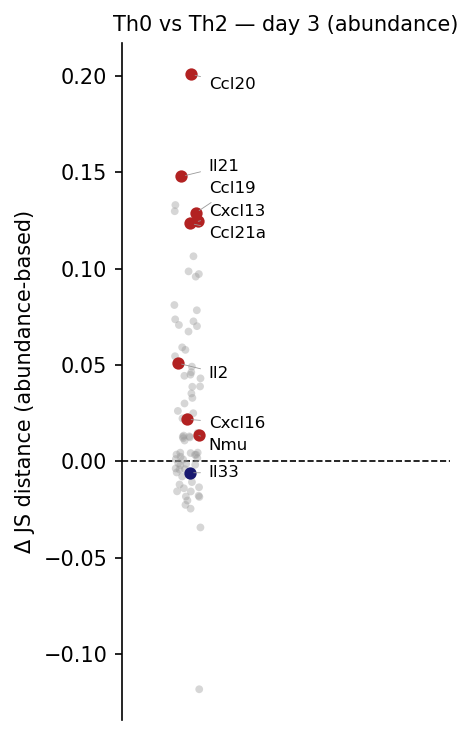

In [25]:
ligands_th2 = ['Ccl19', 'Ccl21a', 'Cxcl13', 'Il21', 'Ccl20', 'Cxcl16',
               'Il33', 'Il2', 'Nmu']

fig, ax = plot_ligand_js_delta_jitter(
    res_th2_d3,
    ligands_to_label=ligands_th2,
    pos_color='firebrick', neg_color='midnightblue',
    title='Th0 vs Th2 — day 3 (abundance)',
)
# plt.savefig(os.path.join(plot_out_dir, 'd3_abundance_Th0vTh2_jitter.pdf'),
#             dpi=300, bbox_inches='tight', transparent=True)
plt.show()

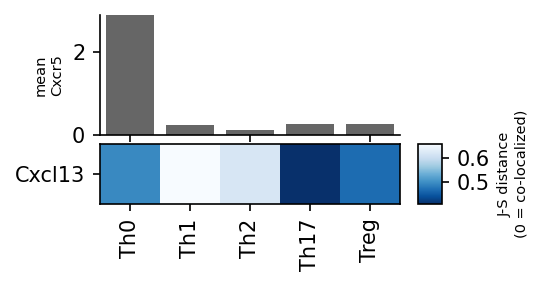

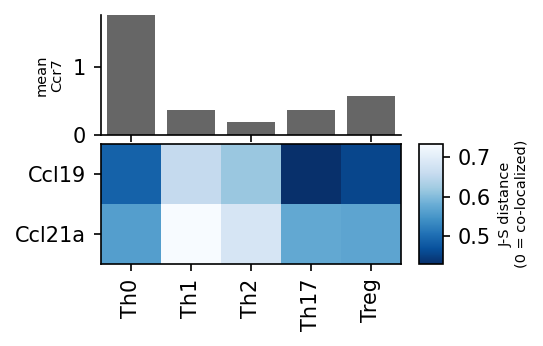

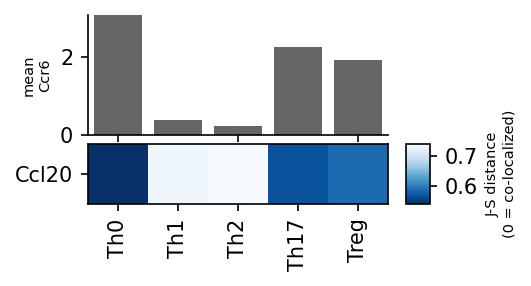

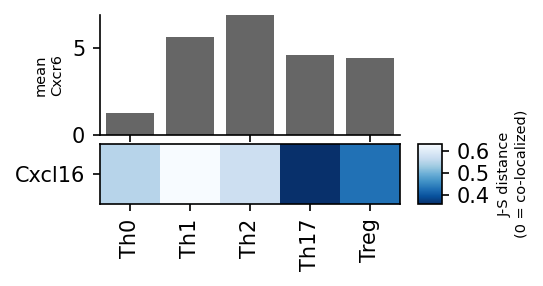

In [30]:
celltypes = ['Th0', 'Th1', 'Th2', 'Th17', 'Treg']
fig, M, fields = plot_ligand_abundance_js_proximity(
    adata,
    receptor='Cxcr5',
    ligands=['Cxcl13'],
    celltype_col='label_fine',
    celltypes=celltypes,
    sample='HDM_day3',
    autoscale=True,
    bin_size_um=50,
    cmap='Blues_r',   
)

fig, M, fields = plot_ligand_abundance_js_proximity(
    adata,
    receptor='Ccr7',
    ligands=['Ccl19','Ccl21a'],
    celltype_col='label_fine',
    celltypes=celltypes,
    sample='HDM_day3',
    autoscale=True,
    bin_size_um=50,
    cmap='Blues_r',   
)

fig, M, fields = plot_ligand_abundance_js_proximity(
    adata,
    receptor='Ccr6',
    ligands=['Ccl20'],
    celltype_col='label_fine',
    celltypes=celltypes,
    sample='HDM_day3',
    autoscale=True,
    bin_size_um=50,
    cmap='Blues_r', 
)

fig, M, fields = plot_ligand_abundance_js_proximity(
    adata,
    receptor='Cxcr6',
    ligands=['Cxcl16'],
    celltype_col='label_fine',
    celltypes=celltypes,
    sample='HDM_day3',
    autoscale=True,
    bin_size_um=50,
    cmap='Blues_r', 
)



In [ ]:
fig = plot_lr_abundance_heatmap(
    res_th2_d3, ca='Th2', cb='Th0',
    top_n=20,
    title='Th0 vs Th2 — day 3 (abundance ΔJS + receptor expression)',
)
plt.savefig(os.path.join(plot_out_dir, 'd3_abundance_Th0vTh2_heatmap.pdf'),
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## Day 3 — Th0 vs Treg

`celltypes=['Treg','Th0']` → `delta = JS_Treg − JS_Th0`; positive = ligand more co-localized with Th0 cell bodies.

In [28]:
res_treg_d3 = rank_ligand_js_delta_abundance(
    adata, df_lr,
    celltypes=['Treg', 'Th0'],
    celltype_col='label_fine',
    sample='HDM_day3',
    bin_size_um=50, smooth_sigma=1.0,
)
res_treg_d3.to_csv(os.path.join(plot_out_dir, 'd3_deltaJS_abundance_Treg-Th0.csv'))
res_treg_d3.head(10)[['ligand','receptor','delta',
                       'frac_pos_Treg','frac_pos_Th0',
                       'mean_recep_Treg','mean_recep_Th0']]

,ligand,receptor,delta,frac_pos_Treg,frac_pos_Th0,mean_recep_Treg,mean_recep_Th0
0,Ccl20,Ccr6,0.046091,0.226051,0.340027,1.938047,3.090409
1,Madcam1,Itgb7,0.023927,0.810164,0.512048,7.328226,4.610323
2,Madcam1,Itga4,0.023927,0.709696,0.653280,6.357211,6.104095
3,Reln,Itgb1,0.018183,0.681659,0.657296,6.052484,6.162197
4,Reln,Itga3,0.018183,0.232477,0.141901,1.956738,1.219910
5,Il21,Il21r,0.017164,0.294977,0.219545,2.481713,1.890417
6,Il21,Il2rg,0.017164,0.827687,0.716198,7.572955,6.643232
7,Ccl21a,Ccr7,0.008253,0.066005,0.202142,0.573018,1.776178
8,Cd40lg,Itga5,-0.023851,0.131425,0.082329,1.085018,0.704264
9,Cd40lg,Itga2b,-0.023851,0.007009,0.008032,0.059163,0.069051


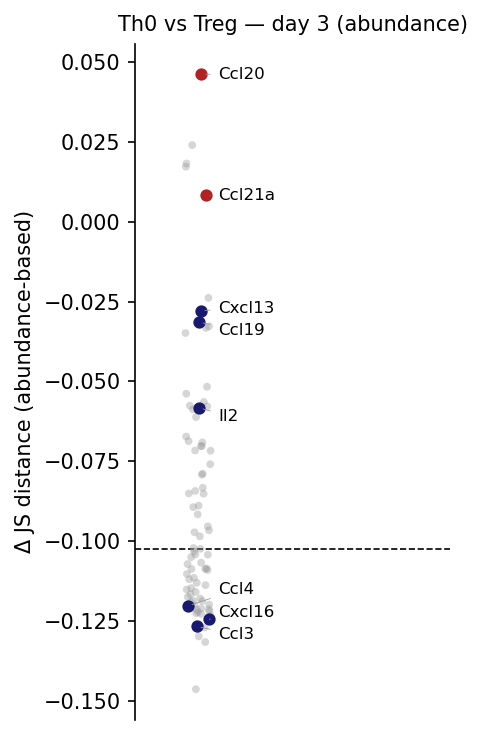

In [30]:
ligands_treg = ['Ccl19', 'Ccl21a', 'Cxcl13', 'Ccl20', 'Cxcl16',
                'Ccl3', 'Ccl4', 'Il2']

fig, ax = plot_ligand_js_delta_jitter(
    res_treg_d3,
    ligands_to_label=ligands_treg,
    pos_color='firebrick', neg_color='midnightblue',
    title='Th0 vs Treg — day 3 (abundance)',
    ref_line = 'median'
)
# plt.savefig(os.path.join(plot_out_dir, 'd3_abundance_Th0vTreg_jitter.pdf'),
#             dpi=300, bbox_inches='tight', transparent=True)
plt.show()

In [ ]:
fig = plot_lr_abundance_heatmap(
    res_treg_d3, ca='Treg', cb='Th0',
    top_n=20,
    title='Th0 vs Treg — day 3 (abundance ΔJS + receptor expression)',
)
plt.savefig(os.path.join(plot_out_dir, 'd3_abundance_Th0vTreg_heatmap.pdf'),
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## Day 3 — Th0 vs Th17

`celltypes=['Th17','Th0']` → `delta = JS_Th17 − JS_Th0`; positive = ligand more co-localized with Th0 cell bodies.

In [ ]:
res_th17_d3 = rank_ligand_js_delta_abundance(
    adata, df_lr,
    celltypes=['Th17', 'Th0'],
    celltype_col='label_fine',
    sample='HDM_day3',
    bin_size_um=50, smooth_sigma=1.0,
)
res_th17_d3.to_csv(plot_out_dir, 'd3_deltaJS_abundance_Th17-Th0.csv'))
res_th17_d3.head(10)[['ligand','receptor','delta',
                       'frac_pos_Th17','frac_pos_Th0',
                       'mean_recep_Th17','mean_recep_Th0']]

In [ ]:
ligands_th17 = ['Ccl19', 'Ccl21a', 'Cxcl13', 'Cxcl16', 'Il18', 'Ccl4']

fig, ax = plot_ligand_js_delta_jitter(
    res_th17_d3,
    ligands_to_label=ligands_th17,
    pos_color='firebrick', neg_color='midnightblue',
    title='Th0 vs Th17 — day 3 (abundance)',
)
plt.savefig(os.path.join(plot_out_dir, 'd3_abundance_Th0vTh17_jitter.pdf'),
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()

In [ ]:
fig = plot_lr_abundance_heatmap(
    res_th17_d3, ca='Th17', cb='Th0',
    top_n=20,
    title='Th0 vs Th17 — day 3 (abundance ΔJS + receptor expression)',
)
plt.savefig(os.path.join(plot_out_dir, 'd3_abundance_Th0vTh17_heatmap.pdf'),
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## Day 30 — Th0 vs Th2

In [ ]:
res_th2_d30 = rank_ligand_js_delta_abundance(
    adata, df_lr,
    celltypes=['Th2', 'Th0'],
    celltype_col='label_fine',
    sample='HDM_day30',
    bin_size_um=50, smooth_sigma=1.0,
)
res_th2_d30.to_csv(plot_out_dir, 'd30_deltaJS_abundance_Th2-Th0.csv'))
res_th2_d30.head(10)[['ligand','receptor','delta',
                       'frac_pos_Th2','frac_pos_Th0',
                       'mean_recep_Th2','mean_recep_Th0']]

In [ ]:
ligands_th2_d30 = ['Ccl19', 'Ccl21a', 'Cxcl13', 'Cxcl9', 'Cxcl10',
                   'Il21', 'Ccl20', 'Cxcl16', 'Il2']

fig, ax = plot_ligand_js_delta_jitter(
    res_th2_d30,
    ligands_to_label=ligands_th2_d30,
    pos_color='firebrick', neg_color='#300018',
    title='Th0 vs Th2 — day 30 (abundance)',
)
plt.savefig(os.path.join(plot_out_dir, 'd30_abundance_Th0vTh2_jitter.pdf'),
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()

In [ ]:
fig = plot_lr_abundance_heatmap(
    res_th2_d30, ca='Th2', cb='Th0',
    top_n=20,
    title='Th0 vs Th2 — day 30 (abundance ΔJS + receptor expression)',
)
plt.savefig(os.path.join(plot_out_dir, 'd30_abundance_Th0vTh2_heatmap.pdf'),
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## Spatial proximity plots — abundance JS + receptor expression bar

Each plot: heatmap color = JS distance between ligand expression (all cells) and cell-type abundance (bright = co-localized); bar = mean receptor expression per cell type.

In [ ]:
celltypes = ['Th0', 'Th1', 'Th2', 'Th17', 'Treg']

### Day 3

In [ ]:
fig, M, fields = plot_ligand_abundance_js_proximity(
    adata,
    receptor='Ccr7',
    ligands=['Ccl19', 'Ccl21a'],
    celltype_col='label_fine',
    celltypes=celltypes,
    sample='HDM_day3',
    autoscale=True,
    bin_size_um=50,
    cmap='Blues_r',
)
plt.savefig(os.path.join(plot_out_dir, 'HDM_day3_abundance_JS_Ccr7_CD4.pdf'),
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()

In [ ]:
fig, M, fields = plot_ligand_abundance_js_proximity(
    adata,
    receptor='Cxcr5',
    ligands=['Cxcl13'],
    celltype_col='label_fine',
    celltypes=celltypes,
    sample='HDM_day3',
    autoscale=True,
    bin_size_um=50,
    cmap='Blues_r',
)
plt.savefig(os.path.join(plot_out_dir, 'HDM_day3_abundance_JS_Cxcr5_CD4.pdf'),
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()

In [ ]:
fig, M, fields = plot_ligand_abundance_js_proximity(
    adata,
    receptor='Il21r',
    ligands=['Il21'],
    celltype_col='label_fine',
    celltypes=celltypes,
    sample='HDM_day3',
    autoscale=True,
    bin_size_um=50,
    cmap='Blues_r',
)
plt.savefig(os.path.join(plot_out_dir, 'HDM_day3_abundance_JS_Il21r_CD4.pdf'),
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()

In [ ]:
fig, M, fields = plot_ligand_abundance_js_proximity(
    adata,
    receptor='Ccr6',
    ligands=['Ccl20'],
    celltype_col='label_fine',
    celltypes=celltypes,
    sample='HDM_day3',
    autoscale=True,
    bin_size_um=50,
    cmap='Blues_r',
)
plt.savefig(os.path.join(plot_out_dir, 'HDM_day3_abundance_JS_Ccr6_CD4.pdf'),
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()


fig, M, fields = plot_ligand_abundance_js_proximity(
    adata,
    receptor='Cxcr6',
    ligands=['Cxcl16'],
    celltype_col='label_fine',
    celltypes=celltypes,
    sample='HDM_day3',
    autoscale=True,
    bin_size_um=50,
    cmap='Blues_r',
)
plt.savefig(os.path.join(plot_out_dir, 'HDM_day3_abundance_JS_Cxcr6_CD4.pdf'),
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()


fig, M, fields = plot_ligand_abundance_js_proximity(
    adata,
    receptor='Il2ra',
    ligands=['Il2'],
    celltype_col='label_fine',
    celltypes=celltypes,
    sample='HDM_day3',
    autoscale=True,
    bin_size_um=50,
    cmap='Blues_r',
)
plt.savefig(os.path.join(plot_out_dir, 'HDM_day3_abundance_JS_Il2ra_CD4.pdf'),
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()

### Day 30

In [ ]:
fig, M, fields = plot_ligand_abundance_js_proximity(
    adata,
    receptor='Ccr7',
    ligands=['Ccl19', 'Ccl21a'],
    celltype_col='label_fine',
    celltypes=celltypes,
    sample='HDM_day30',
    autoscale=True,
    bin_size_um=50,
    cmap='Blues_r',
)
plt.savefig(os.path.join(plot_out_dir, 'HDM_day30_abundance_JS_Ccr7_CD4.pdf'),
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()


fig, M, fields = plot_ligand_abundance_js_proximity(
    adata,
    receptor='Cxcr5',
    ligands=['Cxcl13'],
    celltype_col='label_fine',
    celltypes=celltypes,
    sample='HDM_day30',
    autoscale=True,
    bin_size_um=50,
    cmap='Blues_r',
)
plt.savefig(os.path.join(plot_out_dir, 'HDM_day30_abundance_JS_Cxcr5_CD4.pdf'),
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()

In [ ]:
import session_info
print('active conda environment:', os.path.basename(sys.prefix))
session_info.show()